# 16 · A digital twin of a heat-pump building: calibrate, synchronise, monitor, ask "what if"
**Level 6 · System integration** &nbsp;|&nbsp; Course link: *Module 1 – digital twins of energy systems: a virtual
model, continuously synchronised with measurements of the physical asset, used for monitoring and decisions*

A digital twin is more than a simulation model. It has four ingredients:
1. a **model** of the physics, with parameters **calibrated** on measurements (grey-box system identification);
2. **synchronisation**: the twin's internal states are corrected with live data (here a **Kalman filter**), so it
   also estimates quantities nobody measures;
3. **monitoring**: a gap between twin and reality signals a fault;
4. **what-if analysis**: decisions are tested on the twin before touching the real asset.

The "real" building below is a detailed simulator that the twin never sees; the twin only receives what a smart home
would measure: indoor temperature, heat-pump electricity, outdoor temperature and solar radiation (real London
weather, January–February 2019).

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy.optimize import least_squares
from energy_ai import weather, set_seed, style
style(); set_seed(0)
rng = np.random.default_rng(0)

w = weather(51.51, -0.13, "2016-01-01", "2019-12-31").loc["2019-01-01":"2019-02-28"]
DT = 0.25                                                     # 15-minute steps [h]
idx = pd.date_range(w.index[0], w.index[-1], freq="15min")
T_out = w.temperature_2m.reindex(idx).interpolate().values
G = w.shortwave_radiation.reindex(idx).interpolate().values / 1000          # kW/m²
N = len(idx)
print(f"{N} steps of 15 min | outdoor {T_out.min():.1f} to {T_out.max():.1f} °C")

5661 steps of 15 min | outdoor -5.0 to 17.4 °C


## 1. The physical building (hidden from the twin)
Three thermal masses (indoor air, inner walls, outer envelope), ventilation, solar gains, occupants, and an
air-source heat pump whose efficiency (COP) falls in cold weather, run by a PI thermostat:
21 °C from 06:00 to 22:00, 18 °C at night.

In [2]:
TRUE = dict(C_air=1.2, C_in=6.0, C_env=14.0, R_air_in=0.8, R_in_env=1.5, R_env_out=5.0, R_vent=12.0, A_sol=4.0, a_env=0.4)
cop = lambda To: np.clip(3.4 + 0.09 * (To - 7), 1.8, 5.0)
setpoint = np.where((idx.hour >= 6) & (idx.hour < 22), 21.0, 18.0)
Q_int = np.where((idx.hour >= 7) & (idx.hour < 23), 0.45, 0.2)                  # people, appliances [kW]

def real_building(p=TRUE, setp=setpoint, faults=None):
    faults = faults or {}
    x = np.array([20.0, 20.0, 15.0]); I = 0.0
    Ta, Te, Qhp, Pel = (np.zeros(N) for _ in range(4))
    for k in range(N):
        e = setp[k] - x[0]; I = np.clip(I + e * DT, -5, 20)
        q = np.clip(2.5 * e + 0.6 * I, 0, 7.0)                                 # thermal output [kW]
        c = cop(T_out[k]) * (0.65 if k >= faults.get("cop_drop_from", N) else 1.0)
        r_vent = 2.0 if faults.get("window", (N, N))[0] <= k < faults.get("window", (N, N))[1] else p["R_vent"]
        ta, ti, te = x
        d_ta = ((ti - ta) / p["R_air_in"] + (T_out[k] - ta) / r_vent + q + p["A_sol"] * G[k] + Q_int[k]) / p["C_air"]
        d_ti = ((ta - ti) / p["R_air_in"] + (te - ti) / p["R_in_env"]) / p["C_in"]
        d_te = ((ti - te) / p["R_in_env"] + (T_out[k] - te) / p["R_env_out"] + p["a_env"] * G[k]) / p["C_env"]
        x = x + DT * np.array([d_ta, d_ti, d_te])
        Ta[k], Te[k], Qhp[k], Pel[k] = x[0], x[2], q, q / c
    return Ta, Te, Qhp, Pel

Ta_true, Te_true, Q_true, P_true = real_building()
# what the smart home measures
y_T = Ta_true + 0.15 * rng.standard_normal(N)                                  # thermostat sensor, ±0.15 K
y_P = P_true * (1 + 0.02 * rng.standard_normal(N))                             # electricity meter, ±2 %
Q_meas = y_P * cop(T_out)                                                      # heat delivered, from the COP curve
print(f"heat-pump electricity over 2 months: {y_P.sum() * DT:.0f} kWh | mean COP {Q_true.sum() / P_true.sum():.2f}")

heat-pump electricity over 2 months: 1218 kWh | mean COP 3.13


## 2. Twin model and calibration (grey-box system identification)
The twin is deliberately **simpler** than reality (as every model is): two masses, indoor $T_i$ and envelope $T_e$:
$$C_i\dot T_i = \frac{T_e-T_i}{R_{ie}} + \frac{T_o-T_i}{R_{v}} + Q_{hp} + A\,G + Q_{int},\qquad
C_e\dot T_e = \frac{T_i-T_e}{R_{ie}} + \frac{T_o-T_e}{R_{eo}}$$
Six unknown parameters $(C_i, C_e, R_{ie}, R_{eo}, R_v, A)$ are fitted so that the twin, driven by the measured
inputs, reproduces the measured indoor temperature over **two weeks**. The next two weeks are for validation.

In [3]:
NAMES = ["C_i", "C_e", "R_ie", "R_eo", "R_v", "A"]
def twin_matrices(th):
    Ci, Ce, Rie, Reo, Rv, A = th
    Ac = np.array([[-1 / (Ci * Rie) - 1 / (Ci * Rv), 1 / (Ci * Rie)], [1 / (Ce * Rie), -1 / (Ce * Rie) - 1 / (Ce * Reo)]])
    Bc = np.array([[1 / (Ci * Rv), 1 / Ci, A / Ci, 1 / Ci], [1 / (Ce * Reo), 0, 0, 0]])      # inputs: T_o, Q_hp, G, Q_int
    return np.eye(2) + DT * Ac, DT * Bc

U = np.c_[T_out, Q_meas, G, Q_int]
def simulate_twin(th, k0, k1, x0):
    Ad, Bd = twin_matrices(th); x = np.array(x0, float); out = np.zeros((k1 - k0, 2))
    for j, k in enumerate(range(k0, k1)):
        x = Ad @ x + Bd @ U[k]; out[j] = x
    return out

CAL, VAL = (96 * 7, 96 * 21), (96 * 21, 96 * 35)
def residuals(log_th):
    th = np.exp(log_th)
    return simulate_twin(th, *CAL, [y_T[CAL[0] - 1], y_T[CAL[0] - 1] - 3])[:, 0] - y_T[CAL[0]:CAL[1]]
fit = least_squares(residuals, np.log([1, 10, 1, 5, 10, 3]), bounds=(np.log(0.05), np.log(200)))
theta = np.exp(fit.x)
display(pd.Series(theta, index=NAMES).round(2).to_frame("calibrated value"))

sim_val = simulate_twin(theta, *VAL, [y_T[VAL[0] - 1], y_T[VAL[0] - 1] - 3])
rmse_cal = np.sqrt(np.mean(residuals(fit.x) ** 2))
rmse_val = np.sqrt(np.mean((sim_val[:, 0] - Ta_true[VAL[0]:VAL[1]]) ** 2))
print(f"open-loop twin error: calibration RMSE {rmse_cal:.2f} K | validation RMSE {rmse_val:.2f} K (2 weeks, no data assimilation)")

,calibrated value
C_i,2.08
C_e,17.63
R_ie,1.37
R_eo,3.37
R_v,200.00
A,2.71


open-loop twin error: calibration RMSE 0.34 K | validation RMSE 0.35 K (2 weeks, no data assimilation)


The ventilation resistance $R_v$ runs to its upper bound: the data cannot tell heat lost through ventilation from heat
lost through the envelope, so the fit routes all losses through $R_{ie}+R_{eo}$. This is an **identifiability**
problem, common in grey-box modelling: the twin still predicts well, but that parameter alone has no physical
meaning. More informative data (e.g. a period with windows open) or fixing $R_v$ from an air-tightness test would fix it.

## 3. Synchronisation with a Kalman filter
Open-loop, the twin slowly drifts (model error, unknown disturbances). A **Kalman filter** corrects the twin's
states every 15 minutes with the measured indoor temperature:
$$\text{predict: } \hat x^- = A\hat x + Bu,\ P^- = APA^\top + Q_w \qquad
\text{update: } K = P^-C^\top(CP^-C^\top + R)^{-1},\ \hat x = \hat x^- + K(y - C\hat x^-)$$
The envelope temperature $T_e$ is **never measured**, yet the filter estimates it from how the indoor temperature
responds. (The twin's $T_e$ is a lumped quantity; we compare it with the real building's outer-envelope temperature.)

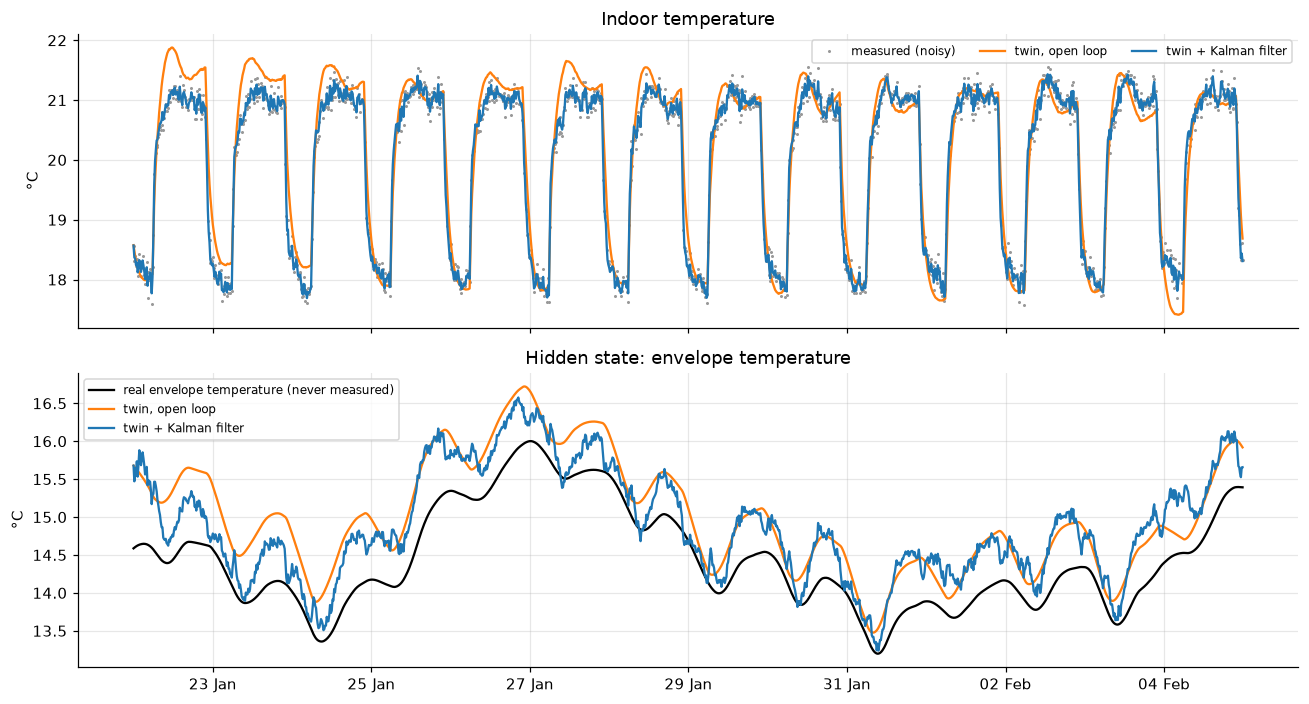

indoor temperature error: open loop 0.35 K | Kalman 0.11 K (the sensor itself has 0.15 K noise)


In [4]:
def kalman(th, k0, k1, q_w=(0.02, 0.01), r=0.15 ** 2, y=y_T):
    Ad, Bd = twin_matrices(th); C = np.array([[1.0, 0.0]])
    x = np.array([y[k0 - 1], y[k0 - 1] - 3]); P = np.eye(2); Qw = np.diag(q_w)
    xs, innov, S_all = np.zeros((k1 - k0, 2)), np.zeros(k1 - k0), np.zeros(k1 - k0)
    for j, k in enumerate(range(k0, k1)):
        x = Ad @ x + Bd @ U[k]; P = Ad @ P @ Ad.T + Qw
        S = (C @ P @ C.T)[0, 0] + r
        innov[j], S_all[j] = y[k] - x[0], S
        K = (P @ C.T)[:, 0] / S
        x = x + K * innov[j]; P = P - np.outer(K, C @ P)
        xs[j] = x
    return xs, innov, S_all

xs, innov, S = kalman(theta, *VAL)
t_val = idx[VAL[0]:VAL[1]]
fig, ax = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
ax[0].plot(t_val, y_T[VAL[0]:VAL[1]], ".", ms=2, color="0.6", label="measured (noisy)")
ax[0].plot(t_val, sim_val[:, 0], color="tab:orange", label="twin, open loop")
ax[0].plot(t_val, xs[:, 0], color="tab:blue", label="twin + Kalman filter")
ax[0].set(ylabel="°C", title="Indoor temperature"); ax[0].legend(fontsize=8, ncol=3)
ax[1].plot(t_val, Te_true[VAL[0]:VAL[1]], "k", label="real envelope temperature (never measured)")
ax[1].plot(t_val, sim_val[:, 1], color="tab:orange", label="twin, open loop")
ax[1].plot(t_val, xs[:, 1], color="tab:blue", label="twin + Kalman filter")
ax[1].set(ylabel="°C", title="Hidden state: envelope temperature"); ax[1].legend(fontsize=8)
ax[1].xaxis.set_major_locator(mdates.DayLocator(interval=2)); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout(); plt.show()
print(f"indoor temperature error: open loop {np.sqrt(np.mean((sim_val[:, 0] - Ta_true[VAL[0]:VAL[1]]) ** 2)):.2f} K | "
      f"Kalman {np.sqrt(np.mean((xs[:, 0] - Ta_true[VAL[0]:VAL[1]]) ** 2)):.2f} K (the sensor itself has 0.15 K noise)")

## 4. Monitoring: the twin as a fault detector
If the real building stops behaving like its twin, the Kalman **innovations** $y - C\hat x^-$ (normalised by their
predicted standard deviation) leave their normal band. We inject two faults into the real building:
a **window left open** for 6 hours, and a **heat-pump efficiency loss of 35 %** (e.g. refrigerant leak).

The COP loss is invisible in the temperature (the thermostat compensates by running longer), but the twin converts
the *metered electricity* into heat with the *nominal* COP, so it believes the house receives more heat than it does.
The 24-hour mean of the innovations reveals this as a persistent negative bias; the dotted line is the lowest value
seen before the fault (set by the transient window event).

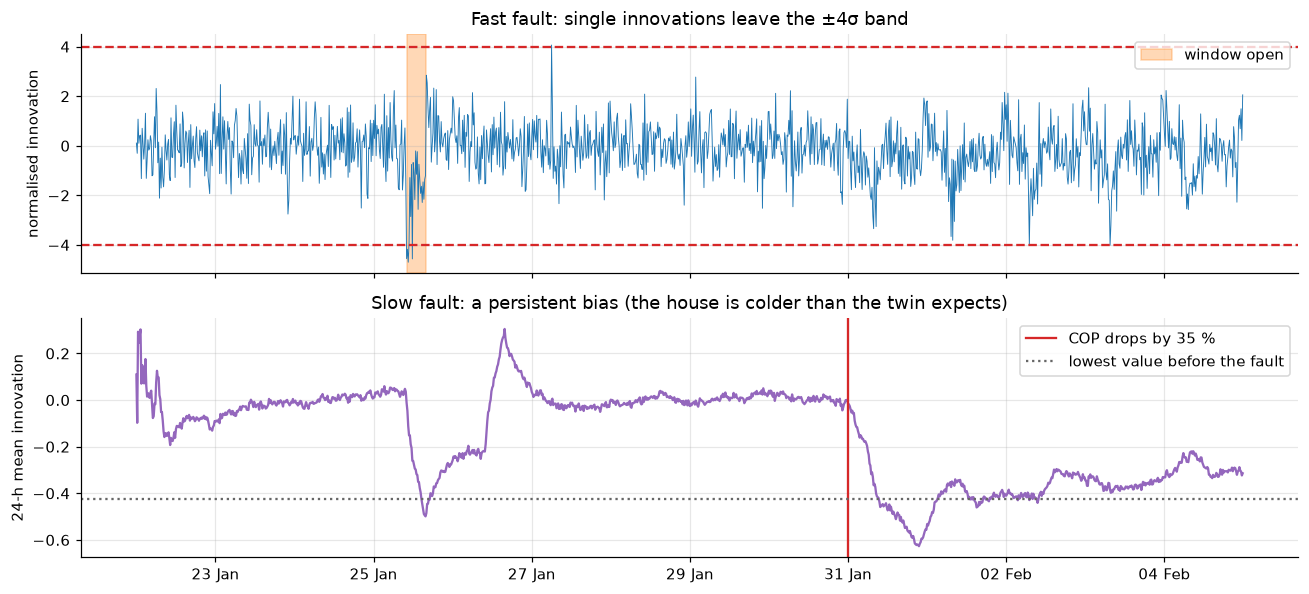

window: first |z| > 4 at 2019-01-25 10:00:00+00:00 (opened 2019-01-25 10:00:00+00:00)
false alarms of the single-sample ±4σ rule in healthy operation: 1 in 768 steps (in practice one requires several consecutive exceedances)
COP loss: 24-h innovation mean drops below its pre-fault minimum at 2019-01-31 14:30:00+00:00 (fault at 2019-01-31 00:00:00+00:00)


In [5]:
k_win, k_cop = VAL[0] + 96 * 3 + 40, VAL[0] + 96 * 9
Ta_f, _, _, P_f = real_building(faults={"window": (k_win, k_win + 24), "cop_drop_from": k_cop})
y_Tf = Ta_f + 0.15 * rng.standard_normal(N)
U_backup = U.copy()
U[:, 1] = P_f * (1 + 0.02 * rng.standard_normal(N)) * cop(T_out)            # the twin's view of the heat input
_, innov_f, S_f = kalman(theta, *VAL, y=y_Tf)
U[:] = U_backup
z = pd.Series(innov_f / np.sqrt(S_f), index=t_val)
z_day = z.rolling(96, min_periods=1).mean()                                  # slow faults: 24-h average of innovations
fig, ax = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
ax[0].plot(z, lw=0.6); ax[0].axhline(4, color="tab:red", ls="--"); ax[0].axhline(-4, color="tab:red", ls="--")
ax[0].axvspan(idx[k_win], idx[k_win + 24], color="tab:orange", alpha=0.3, label="window open")
ax[0].set(ylabel="normalised innovation", title="Fast fault: single innovations leave the ±4σ band"); ax[0].legend()
ax[1].plot(z_day, color="tab:purple"); ax[1].axvline(idx[k_cop], color="tab:red", label="COP drops by 35 %")
ax[1].axhline(np.quantile(z_day[: k_cop - VAL[0]], 0.01), color="0.4", ls=":", label="lowest value before the fault")
ax[1].set(ylabel="24-h mean innovation", title="Slow fault: a persistent bias (the house is colder than the twin expects)"); ax[1].legend()
ax[1].xaxis.set_major_locator(mdates.DayLocator(interval=2)); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout(); plt.show()
print(f"window: first |z| > 4 at {z[(z.abs() > 4) & (z.index >= idx[k_win])].index.min()} (opened {idx[k_win]})")
healthy = (z.index < idx[k_cop]) & ~((z.index >= idx[k_win]) & (z.index < idx[k_win + 96]))
print(f"false alarms of the single-sample ±4σ rule in healthy operation: {(z[healthy].abs() > 4).sum()} in {healthy.sum()} steps "
      f"(in practice one requires several consecutive exceedances)")
before = z_day[: k_cop - VAL[0]]
alarm = z_day[(z_day < before.min()) & (z_day.index > idx[k_cop])].index.min()
print(f"COP loss: 24-h innovation mean drops below its pre-fault minimum at {alarm} (fault at {idx[k_cop]})")

## 5. What-if: a lower night set-point
Before changing the real thermostat, ask the twin: *how much electricity does a 16 °C night set-point save?* The twin
is run with its own thermostat and heat-pump model; the real building answers the same question for comparison.

In [6]:
def twin_with_thermostat(th, setp, k0, k1):
    Ad, Bd = twin_matrices(th); x = np.array([Ta_true[k0 - 1], Te_true[k0 - 1]]); I = 0.0; E = 0.0
    for k in range(k0, k1):
        e = setp[k] - x[0]; I = np.clip(I + e * DT, -5, 20); q = np.clip(2.5 * e + 0.6 * I, 0, 7.0)
        x = Ad @ x + Bd @ np.array([T_out[k], q, G[k], Q_int[k]]); E += q / cop(T_out[k]) * DT
    return E

night16 = np.where((idx.hour >= 6) & (idx.hour < 22), 21.0, 16.0)
k0, k1 = VAL
e_twin = [twin_with_thermostat(theta, sp_, k0, k1) for sp_ in (setpoint, night16)]
e_real = [real_building(setp=sp_)[3][k0:k1].sum() * DT for sp_ in (setpoint, night16)]
display(pd.DataFrame({"twin": e_twin, "real building": e_real}, index=["18 °C at night", "16 °C at night"]).T.assign(
    **{"saving": lambda d: 1 - d["16 °C at night"] / d["18 °C at night"]}).style.format({"18 °C at night": "{:.0f} kWh", "16 °C at night": "{:.0f} kWh", "saving": "{:.1%}"}))

,18 °C at night,16 °C at night,saving
twin,384 kWh,365 kWh,5.1%
real building,383 kWh,363 kWh,5.0%


## Key takeaways
* A digital twin = **calibrated model + live synchronisation + monitoring + what-if**. A simple grey-box model with six
  physically meaningful parameters is enough when it is continuously corrected by data.
* The **Kalman filter** fuses model and measurements, and estimates quantities that are never measured (here the
  envelope temperature): a *virtual sensor*.
* **Innovations** (twin vs reality) are a principled fault detector: fast faults show as spikes, slow degradation as a
  persistent bias, even when a controller hides the symptom in the measured temperature.
* The twin answers what-if questions before anything is changed in the real asset; its answer is only as good as its
  calibration, so always validate on data not used for fitting.